# Cemento en segundos con plasma: ¿cumple la norma, cuánto cuesta y cuánto CO₂ ahorra?

**Hacer cemento suelta unos 900 kg de CO₂ por cada tonelada de clínker**, según las cuentas de los autores (el clínker son las piedritas que salen del horno y que, molidas con yeso, se vuelven cemento). Un equipo cambió el horno de llamas por un plasma de carbono encendido con microondas: la cocción pasa de horas a segundos, con puntos que llegan hasta 2.400 °C. ¿Sale un clínker que cumple la norma? Y si se hiciera a escala, ¿cuánto costaría y cuánto CO₂ ahorraría?

**Paper:** Zheng et al. (2026). *Sustainable cement production via a liquid-phase pathway*. **Nature**.
**DOI:** [10.1038/s41586-026-11313-w](https://doi.org/10.1038/s41586-026-11313-w)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-25-cemento-plasma-microondas-fase-liquida/notebook.ipynb)

**Video:** Pendiente

El cemento Portland se fabrica casi igual desde hace dos siglos: caliza y arcilla molidas entran a un horno rotatorio que las calienta durante horas hasta formar el clínker. El CO₂ sale por dos lados: la caliza (carbonato de calcio) lo suelta al descomponerse (descarbonatación) y el combustible que calienta el horno suma el resto.

La propuesta del equipo es calentar con electricidad. Un plasma de carbono excitado con microondas funde la materia prima en segundos; en ese líquido los elementos se mezclan y al solidificarse forman las fases del clínker. Probaron tres clínkeres:

- **COMM**: clínker comercial, de horno rotatorio (la referencia).
- **NEW**: harina cruda tradicional (caliza + arcilla) cocida con el plasma.
- **RCL**: pasta de cemento endurecida sacada de concreto de demolición, cocida con el plasma.

El paper está tras un muro de pago, pero su material suplementario (Supplementary Information, SI) es público. Vamos a abrir los números que trae: la composición de los tres clínkeres (SI), las entradas y resultados del modelo de costos de los autores, y las cuentas de CO₂ que aparecen en el expediente de revisión por pares (*Peer Review File*). Dos curvas de costo solo existían como figuras: las digitalizamos punto por punto.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
PRECIO_KWH = 0.07        # USD por kWh (0,07 = tarifa industrial media de EE. UU. según el SI)
FACTOR_RED = 0.37        # kg CO₂ por kWh (0,37 = red promedio de EE. UU.; 0 = renovable)
KWH_POR_TONELADA = 819   # electricidad por tonelada: pendiente de la figura R6 (710 = solo el sinterizado)
FUENTE = 'Fuente: Zheng et al. (2026), Nature | Datos: Supplementary Information y Peer Review File del paper'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SEC = '#059669'
COLOR_VIOLETA = '#7C3AED'
COLOR_GRIS = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-25-cemento-plasma-microondas-fase-liquida'
ARCHIVOS = ['fases_clinker_rietveld.csv', 'costo_vs_precio_electricidad.csv', 'costo_vs_capacidad.csv',
            'escenarios_costo_texto.csv', 'costo_cemento_convencional.csv', 'co2_por_tonelada.csv',
            'reduccion_global_co2.csv', 'tea_entradas.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles, signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d),(?=\d{3}(?!\d))', '_', s)   # separador de miles
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# ── Carga ──
fases = pd.read_csv('datos/fases_clinker_rietveld.csv')          # Rietveld, SI Figs. S7-S9
r6 = pd.read_csv('datos/costo_vs_precio_electricidad.csv')       # Peer Review File Fig. R6 (digitalizada)
cap = pd.read_csv('datos/costo_vs_capacidad.csv')                # SI Fig. S21 (digitalizada)
esc = pd.read_csv('datos/escenarios_costo_texto.csv')            # cifras citadas en el texto del SI y la revisión
conv = pd.read_csv('datos/costo_cemento_convencional.csv')       # SI p. 27
co2 = pd.read_csv('datos/co2_por_tonelada.csv')                  # Peer Review File R14
glob = pd.read_csv('datos/reduccion_global_co2.csv')             # SI Tabla S3
tea = pd.read_csv('datos/tea_entradas.csv').set_index('parametro')  # SI Tabla S2

fases['silicatos_pct'] = fases['alita_pct'] + fases['belita_pct']
pr(f'Clínkeres: {len(fases)} (una refinación Rietveld por clínker, sin réplicas)')
pr(f'Curva costo vs. electricidad: {len(r6)} puntos | curva costo vs. capacidad: {len(cap)} puntos')
pr(f"Electricidad del sinterizado con plasma (Tabla S2): {tea.loc['electricidad_sinterizado_plasma', 'valor_min']:.0f} kWh/t")
pr(f"Capacidad del caso base (Tabla S2): {tea.loc['capacidad_sistema', 'valor_min']:,.0f} t de cemento al año")

Clínkeres: 3 (una refinación Rietveld por clínker, sin réplicas)
Curva costo vs. electricidad: 15 puntos | curva costo vs. capacidad: 11 puntos
Electricidad del sinterizado con plasma (Tabla S2): 710 kWh/t
Capacidad del caso base (Tabla S2): 500.000 t de cemento al año


## ¿Sale un clínker que sirva?

Aquí está.

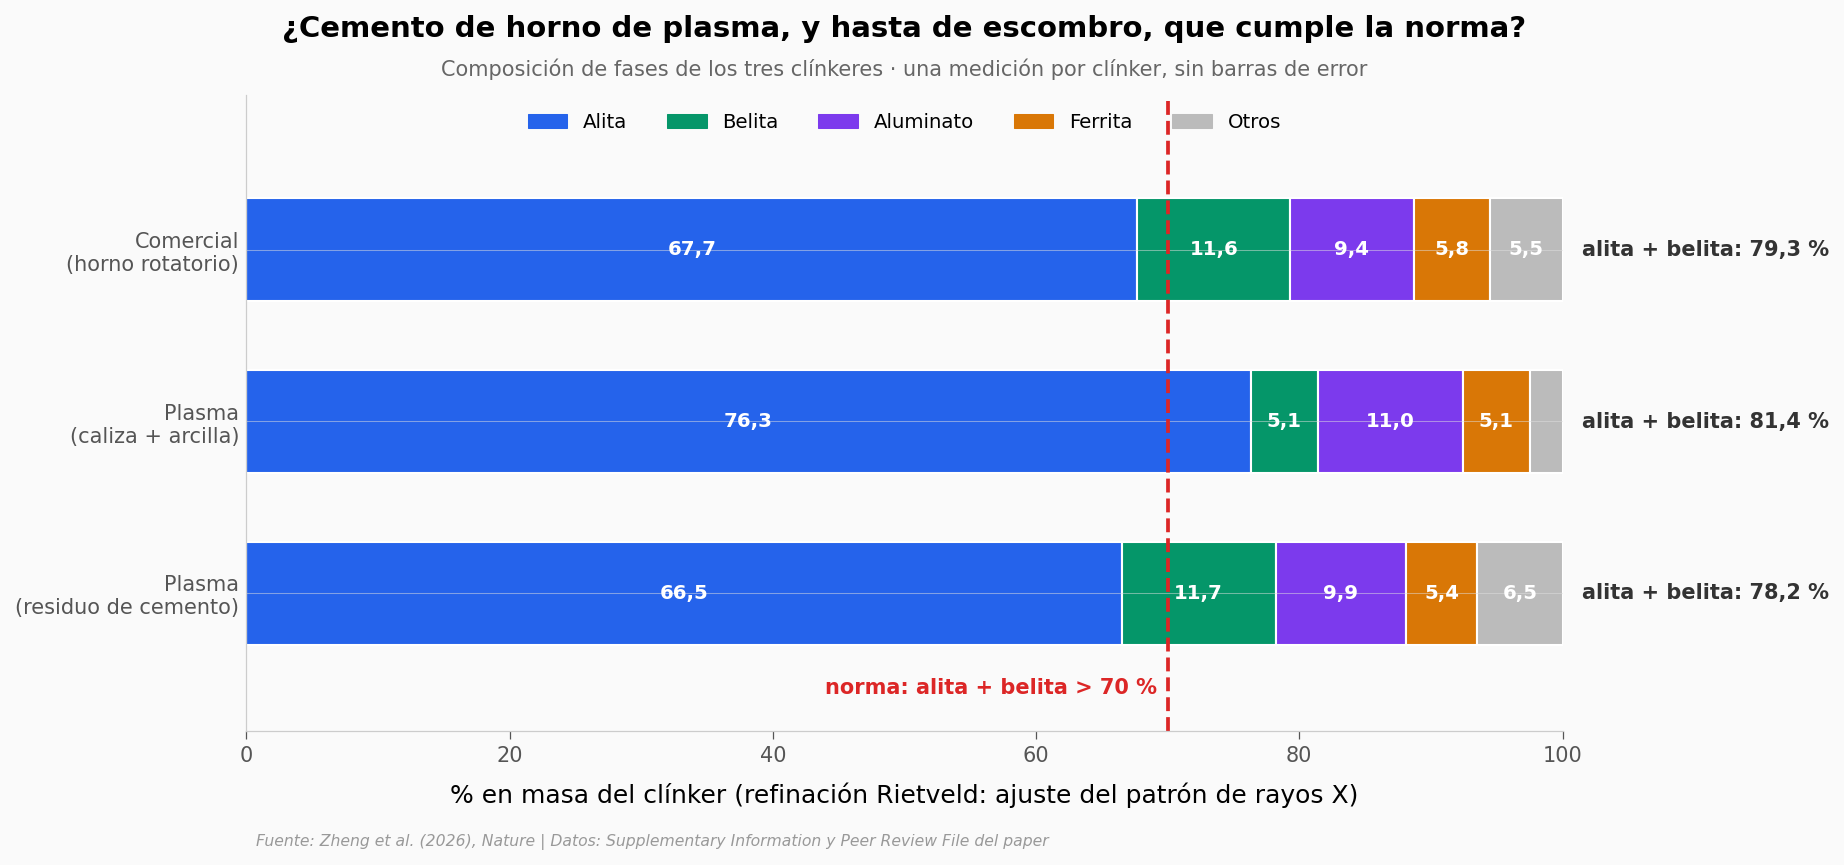

COMM: alita 67,7 % · belita 11,6 % · alita + belita 79,3 % (margen sobre la norma: +9,3 puntos)
NEW: alita 76,3 % · belita 5,1 % · alita + belita 81,4 % (margen sobre la norma: +11,4 puntos)
RCL: alita 66,5 % · belita 11,7 % · alita + belita 78,2 % (margen sobre la norma: +8,2 puntos)
NEW − COMM: alita +8,6 pp · belita −6,5 pp
RCL − COMM: alita −1,2 pp · belita +0,1 pp


In [2]:
UMBRAL_NORMA = 70  # % en masa de alita + belita que exige la norma del cemento Portland (Peer Review File)
nombres = {'COMM': 'Comercial\n(horno rotatorio)', 'NEW': 'Plasma\n(caliza + arcilla)',
           'RCL': 'Plasma\n(residuo de cemento)'}
orden = ['RCL', 'NEW', 'COMM']
f = fases.set_index('clinker').loc[orden]
componentes = [('alita_pct', 'Alita', COLOR_DATOS), ('belita_pct', 'Belita', COLOR_SEC),
               ('aluminato_pct', 'Aluminato', COLOR_VIOLETA), ('ferrita_pct', 'Ferrita', COLOR_REFERENCIA),
               ('otros_pct', 'Otros', COLOR_GRIS)]

fig, ax = plt.subplots(figsize=(13, 5.5))
y = np.arange(len(orden))
izq = np.zeros(len(orden))
for col, nombre, color in componentes:
    v = f[col].values
    ax.barh(y, v, left=izq, color=color, height=0.6, edgecolor='white', linewidth=1)
    for i in range(len(orden)):
        if v[i] >= 5:
            ax.text(izq[i] + v[i] / 2, y[i], es(f'{v[i]:.1f}'), ha='center', va='center',
                    fontsize=9.5, color='white', fontweight='bold')
    izq += v
for i, c in enumerate(orden):
    s = f.loc[c, 'silicatos_pct']
    ax.text(101.5, y[i], f"alita + belita: {es(f'{s:.1f}')} %", va='center',
            fontsize=10, color='#333333', fontweight='bold')
ax.axvline(UMBRAL_NORMA, color=COLOR_ALERTA, linestyle='--', linewidth=1.8)
ax.text(UMBRAL_NORMA - 0.8, -0.55, 'norma: alita + belita > 70 %', color=COLOR_ALERTA,
        fontsize=10, fontweight='bold', ha='right', va='center')
ax.set_yticks(y)
ax.set_yticklabels([nombres[c] for c in orden], fontsize=10)
ax.set_xlim(0, 100)
ax.set_ylim(-0.8, len(orden) - 0.1)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=n) for _, n, c in componentes], loc='upper center',
          bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=9.5, frameon=False)
ax.set_xlabel('% en masa del clínker (refinación Rietveld: ajuste del patrón de rayos X)')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿Cemento de horno de plasma, y hasta de escombro, que cumple la norma?',
             fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Composición de fases de los tres clínkeres · una medición por clínker, sin barras de error',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
plt.subplots_adjust(right=0.8)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/fases_clinker.png', dpi=200, bbox_inches='tight')
plt.show()

com = fases.set_index('clinker')
for c in ['COMM', 'NEW', 'RCL']:
    pr(f"{c}: alita {com.loc[c, 'alita_pct']:.1f} % · belita {com.loc[c, 'belita_pct']:.1f} % · "
       f"alita + belita {com.loc[c, 'silicatos_pct']:.1f} % (margen sobre la norma: {com.loc[c, 'silicatos_pct'] - UMBRAL_NORMA:+.1f} puntos)")
pr(f"NEW − COMM: alita {com.loc['NEW', 'alita_pct'] - com.loc['COMM', 'alita_pct']:+.1f} pp · belita {com.loc['NEW', 'belita_pct'] - com.loc['COMM', 'belita_pct']:+.1f} pp")
pr(f"RCL − COMM: alita {com.loc['RCL', 'alita_pct'] - com.loc['COMM', 'alita_pct']:+.1f} pp · belita {com.loc['RCL', 'belita_pct'] - com.loc['COMM', 'belita_pct']:+.1f} pp")

Los tres pasan la línea. La norma del cemento Portland pide más de 70 % en masa de alita + belita, los silicatos de calcio que le dan la resistencia al reaccionar con el agua. El comercial suma 79,3 %, el de plasma con materia prima tradicional (NEW) 81,4 % y el hecho con residuo de cemento (RCL) 78,2 %.

Lo que cambia es la mezcla. El NEW tiene 8,6 puntos más de alita (la fase que endurece rápido) y 6,5 puntos menos de belita que el comercial; el SI lo atribuye, con un "probablemente", a la temperatura alta y al enfriamiento rápido. El RCL queda casi calcado al comercial: 1,2 puntos menos de alita.

Ojo con dos cosas. Es **una sola** refinación Rietveld (un ajuste del patrón de rayos X) por clínker, sin réplicas ni barras de error: no podemos saber si 8,6 puntos superan la variación de un lote a otro. Y la composición no lo es todo: la resistencia a la compresión y el calor de hidratación vienen en el paper solo como imágenes, así que no los reproducimos.

## ¿Cuánto costaría?

Desde aquí los números ya no salen de un laboratorio sino de un modelo tecnoeconómico (TEA, del inglés *techno-economic analysis*) de los autores: una planta hipotética con entradas supuestas. Según el texto del SI, lo que más pesa en el costo es el precio de la electricidad.

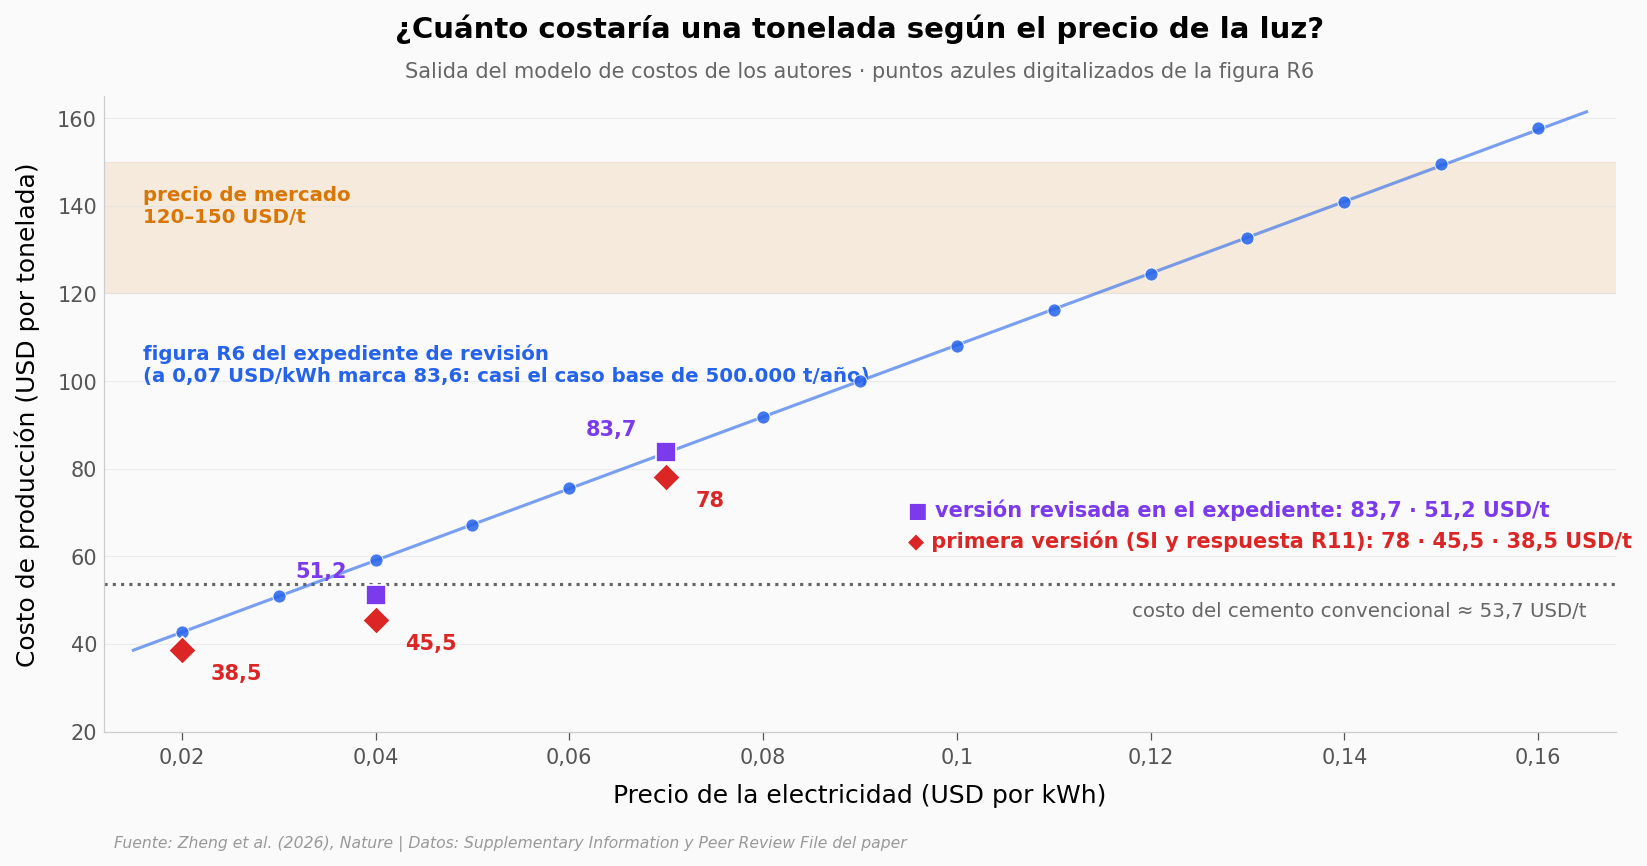

Ajuste R6: pendiente 819 kWh/t · costo sin electricidad 26,3 USD/t · R² = 0,99998 · n = 15
Figura R6 leída a 0,02 / 0,04 / 0,07 USD/kWh: 42,8 / 59,1 / 83,6 USD/t
Participación de la energía según la pendiente de R6, a 0,07 USD/kWh: 68,6 %
Versión del SI (78 USD/t, 72 % energía): 802 kWh/t implícitos · 21,8 USD/t sin electricidad
  esperado a 0,04 → 53,9 USD/t (texto: 45,5) · a 0,02 → 37,9 USD/t (texto: 38,5)
  precio de la luz que daría 45,5 USD/t con esa cuenta: 0,0295 USD/kWh
Versión revisada (83,7 USD/t, 83 % energía): 992 kWh/t implícitos
Convencional: 18,4 + 22,5 + 12,8 = 53,7 USD/t · brecha a 0,07 USD/kWh: +24,3 (versión del SI) / +30,0 USD/t (versión revisada)


In [3]:
# Ajuste lineal a la figura R6 (costo vs. precio de la electricidad)
m, b = np.polyfit(r6['precio_usd_kwh'], r6['costo_usd_t'], 1)
pred = m * r6['precio_usd_kwh'] + b
r2 = 1 - ((r6['costo_usd_t'] - pred) ** 2).sum() / ((r6['costo_usd_t'] - r6['costo_usd_t'].mean()) ** 2).sum()
pto = r6.set_index('precio_usd_kwh')['costo_usd_t']

# El expediente de revisión trae dos versiones de la misma frase sobre el costo
con_precio = esc.dropna(subset=['precio_usd_kwh'])
revisada = con_precio[con_precio['fuente'].str.contains('revisada')]
version_si = con_precio[~con_precio['fuente'].str.contains('revisada')]
ENERGIA_SI, ENERGIA_REVISADA = 0.72, 0.83     # participación de la energía que dice cada versión del texto
base78 = version_si.set_index('precio_usd_kwh').loc[0.07, 'costo_usd_t']
base_rev = revisada.set_index('precio_usd_kwh').loc[0.07, 'costo_usd_t']

# Dentro de la versión del SI: 78 USD/t con 72 % de energía
kwh_implicito = ENERGIA_SI * base78 / 0.07
no_energia = (1 - ENERGIA_SI) * base78
def costo_desde_78(p):
    return no_energia + kwh_implicito * p
costo_conv = conv['usd_t'].sum()
MERCADO = (120, 150)

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axhspan(*MERCADO, color=COLOR_REFERENCIA, alpha=0.12, zorder=0)
ax.text(0.016, 140, 'precio de mercado\n120–150 USD/t', color=COLOR_REFERENCIA, fontsize=9.5,
        fontweight='bold', ha='left', va='center')
ax.axhline(costo_conv, color='#666666', linestyle=':', linewidth=1.5)
ax.text(0.165, costo_conv - 4, f"costo del cemento convencional ≈ {es(f'{costo_conv:.1f}')} USD/t",
        color='#666666', fontsize=9.5, ha='right', va='top')
xs = np.linspace(0.015, 0.165, 50)
ax.plot(xs, m * xs + b, color=COLOR_DATOS, linewidth=1.5, alpha=0.6)
ax.scatter(r6['precio_usd_kwh'], r6['costo_usd_t'], color=COLOR_DATOS, s=40, alpha=0.85,
           edgecolors='white', linewidths=0.5, zorder=5)
ax.text(0.016, 100, 'figura R6 del expediente de revisión\n(a 0,07 USD/kWh marca 83,6: casi el caso base de 500.000 t/año)',
        color=COLOR_DATOS, fontsize=9.5, fontweight='bold', ha='left')
ax.scatter(version_si['precio_usd_kwh'], version_si['costo_usd_t'], color=COLOR_ALERTA, s=90, marker='D',
           edgecolors='white', linewidths=0.8, zorder=6)
ax.scatter(revisada['precio_usd_kwh'], revisada['costo_usd_t'], color=COLOR_VIOLETA, s=90, marker='s',
           edgecolors='white', linewidths=0.8, zorder=7)
for _, r in version_si.iterrows():
    ax.text(r.precio_usd_kwh + 0.003, r.costo_usd_t - 3, es(f'{r.costo_usd_t:g}'), color=COLOR_ALERTA,
            fontsize=10, fontweight='bold', va='top')
for _, r in revisada.iterrows():
    ax.text(r.precio_usd_kwh - 0.003, r.costo_usd_t + 3, es(f'{r.costo_usd_t:g}'), color=COLOR_VIOLETA,
            fontsize=10, fontweight='bold', ha='right', va='bottom')
ax.text(0.095, 62, '◆ primera versión (SI y respuesta R11): 78 · 45,5 · 38,5 USD/t', color=COLOR_ALERTA, fontsize=10, fontweight='bold')
ax.text(0.095, 69, '■ versión revisada en el expediente: 83,7 · 51,2 USD/t', color=COLOR_VIOLETA,
        fontsize=10, fontweight='bold')
ax.set_xlim(0.012, 0.168)
ax.set_ylim(20, 165)
ax.set_xlabel('Precio de la electricidad (USD por kWh)')
ax.set_ylabel('Costo de producción (USD por tonelada)')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿Cuánto costaría una tonelada según el precio de la luz?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Salida del modelo de costos de los autores · puntos azules digitalizados de la figura R6',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/costo_vs_electricidad.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Ajuste R6: pendiente {m:.0f} kWh/t · costo sin electricidad {b:.1f} USD/t · R² = {r2:.5f} · n = {len(r6)}')
pr(f'Figura R6 leída a 0,02 / 0,04 / 0,07 USD/kWh: {pto[0.02]:.1f} / {pto[0.04]:.1f} / {pto[0.07]:.1f} USD/t')
pr(f'Participación de la energía según la pendiente de R6, a 0,07 USD/kWh: {m * 0.07 / pto[0.07] * 100:.1f} %')
pr(f'Versión del SI ({base78:g} USD/t, {ENERGIA_SI*100:.0f} % energía): {kwh_implicito:.0f} kWh/t implícitos · {no_energia:.1f} USD/t sin electricidad')
pr(f'  esperado a 0,04 → {costo_desde_78(0.04):.1f} USD/t (texto: 45,5) · a 0,02 → {costo_desde_78(0.02):.1f} USD/t (texto: 38,5)')
pr(f'  precio de la luz que daría 45,5 USD/t con esa cuenta: {(45.5 - no_energia) / kwh_implicito:.4f} USD/kWh')
pr(f'Versión revisada ({base_rev:g} USD/t, {ENERGIA_REVISADA*100:.0f} % energía): {ENERGIA_REVISADA * base_rev / 0.07:.0f} kWh/t implícitos')
pr(f'Convencional: {" + ".join(f"{v:.1f}" for v in conv["usd_t"])} = {costo_conv:.1f} USD/t · '
   f'brecha a 0,07 USD/kWh: {base78 - costo_conv:+.1f} (versión del SI) / {base_rev - costo_conv:+.1f} USD/t (versión revisada)')

Los 15 puntos de la figura caen sobre una recta casi perfecta (R² = 0,99998). Su pendiente dice cuánta electricidad le carga el modelo a cada tonelada: 819 kWh. Y si la luz fuera gratis, quedarían unos 26,3 USD/t de todo lo demás.

El expediente de revisión trae **dos versiones** de la misma frase sobre el costo: la que quedó en el SI publicado y una revisada que los autores proponen en su respuesta a los revisores.

| Precio de la luz | Primera versión: SI y respuesta R11 (rombos rojos) | Versión revisada en el expediente (cuadrados violeta) | Figura R6 |
|---|---|---|---|
| 0,07 USD/kWh | 78 USD/t, energía ≈ 72 % | 83,7 USD/t, energía ≈ 83 % | 83,6 USD/t |
| 0,04 USD/kWh | 45,5 USD/t | 51,2 USD/t | 59,1 USD/t |
| 0,02 USD/kWh | 38,5 USD/t (solo en la respuesta R11, que cita la figura R6) | — | 42,8 USD/t |

La figura R6 casa con el 83,7 de la versión revisada a 0,07 USD/kWh, pero ninguna de las dos versiones cuadra del todo con ella. A 0,04 USD/kWh la figura marca 59,1 USD/t, por encima de 45,5 y de 51,2. Y con su pendiente la electricidad pesa el 68,6 % del costo a 0,07 USD/kWh, no el 72 % ni el 83 % que dicen las versiones.

La primera versión tampoco cuadra por dentro, si suponemos que lo que no es electricidad cuesta lo mismo a cualquier precio de la luz. 78 USD/t con 72 % de energía implica 802 kWh/t; con esa cuenta, a 0,02 USD/kWh saldrían 37,9 USD/t (cerca de los 38,5 de la respuesta R11), pero a 0,04 saldrían 53,9, no 45,5. Ese 45,5 corresponde a una luz de unos 0,0295 USD/kWh. El SI publicado conserva esta versión, y no podemos ver la figura 4e final, tras el muro de pago, para saber cuál quedó en el paper.

¿Y frente al cemento de siempre? Sumando los componentes que da el SI, el convencional cuesta 53,7 USD/t (el texto lo redondea a "unos 50"). A 0,07 USD/kWh, el de plasma sale entre 24,3 y 30,0 USD/t más caro, según la versión. Los dos quedan por debajo del precio de mercado de 120 a 150 USD/t; por eso los autores plantean que podría competir, sobre todo donde la electricidad es barata.

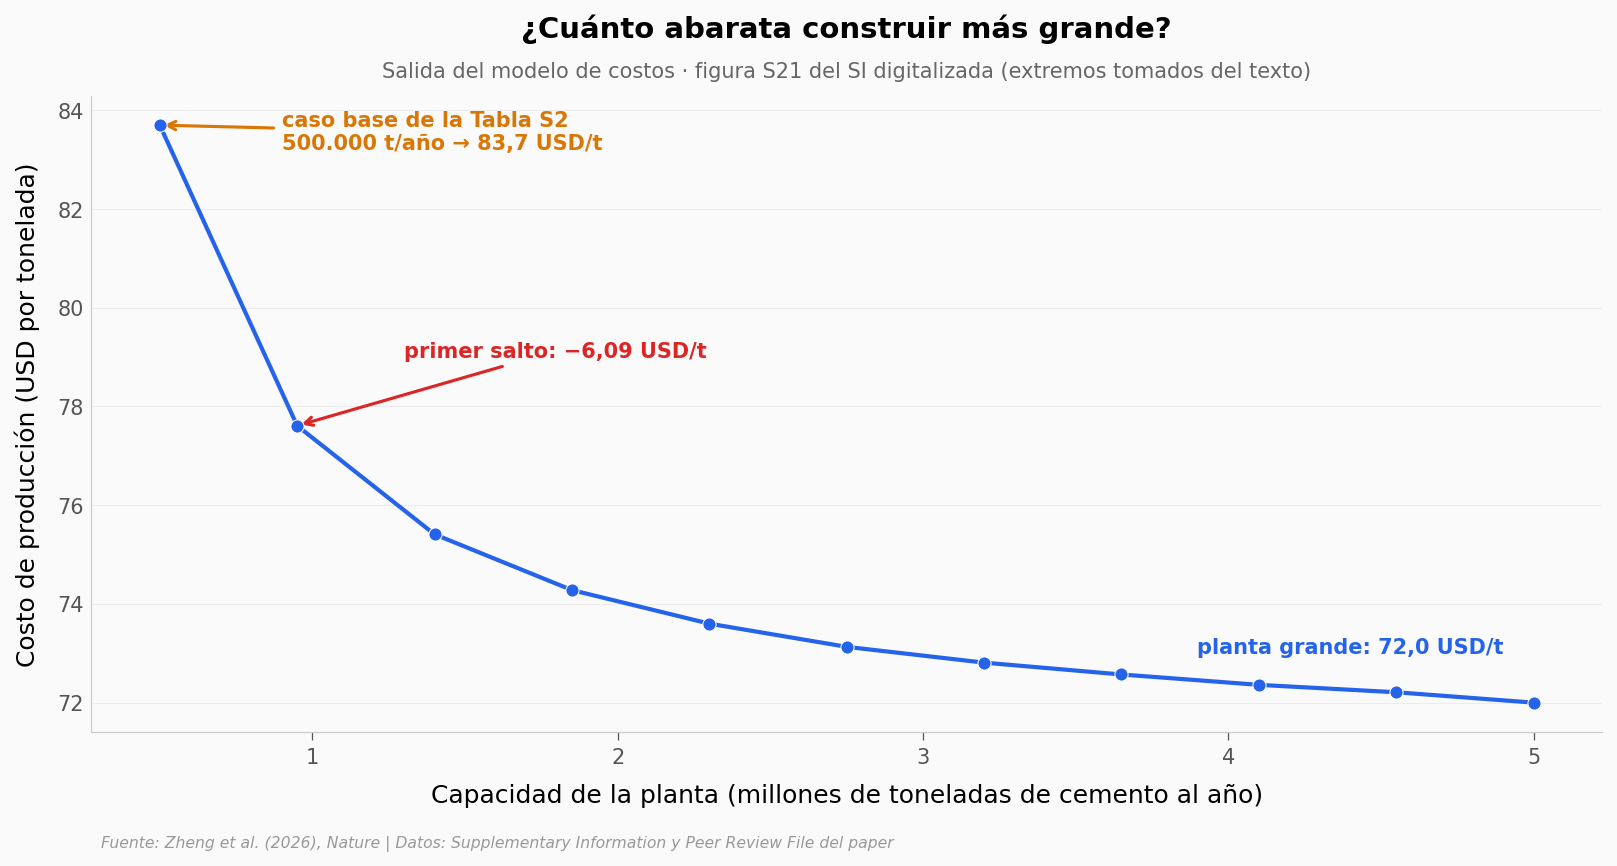

De 0,5 a 5,0 Mt/año: 83,7 → 72,0 USD/t (−14,0 %, 11,7 USD/t)
Primer tramo (0,5 → 0,95 Mt): −6,09 USD/t (52,1 % de la bajada) · último tramo: −0,21 USD/t


In [4]:
cap_mt = cap['capacidad_t_anio'] / 1e6
cap_base = tea.loc['capacidad_sistema', 'valor_min']
c = cap['costo_usd_t']

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(cap_mt, c, color=COLOR_DATOS, linewidth=2)
ax.scatter(cap_mt, c, color=COLOR_DATOS, s=40, edgecolors='white', linewidths=0.5, zorder=5)
ax.annotate(f"caso base de la Tabla S2\n{es(f'{cap_base:,.0f}')} t/año → {es(f'{c.iloc[0]:.1f}')} USD/t",
            xy=(cap_base / 1e6, c.iloc[0]), xytext=(0.9, 83.2), fontsize=10,
            color=COLOR_REFERENCIA, fontweight='bold', arrowprops=dict(arrowstyle='->', color=COLOR_REFERENCIA, lw=1.5))
ax.annotate(f"primer salto: {es(f'{c.iloc[1] - c.iloc[0]:+.2f}')} USD/t", xy=(cap_mt.iloc[1], c.iloc[1]),
            xytext=(1.3, 79), fontsize=10, color=COLOR_ALERTA, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=COLOR_ALERTA, lw=1.5))
ax.text(4.9, c.iloc[-1] + 1.0, f"planta grande: {es(f'{c.iloc[-1]:.1f}')} USD/t",
        color=COLOR_DATOS, fontsize=10, fontweight='bold', ha='right')
ax.set_xlabel('Capacidad de la planta (millones de toneladas de cemento al año)')
ax.set_ylabel('Costo de producción (USD por tonelada)')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Cuánto abarata construir más grande?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Salida del modelo de costos · figura S21 del SI digitalizada (extremos tomados del texto)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/costo_vs_capacidad.png', dpi=200, bbox_inches='tight')
plt.show()

bajada = c.iloc[0] - c.iloc[-1]
pr(f'De {cap_mt.iloc[0]:.1f} a {cap_mt.iloc[-1]:.1f} Mt/año: {c.iloc[0]:.1f} → {c.iloc[-1]:.1f} USD/t '
   f'({(c.iloc[-1]/c.iloc[0]-1)*100:+.1f} %, {bajada:.1f} USD/t)')
pr(f'Primer tramo (0,5 → 0,95 Mt): {c.iloc[1]-c.iloc[0]:+.2f} USD/t ({(c.iloc[0]-c.iloc[1]) / bajada * 100:.1f} % de la bajada) · '
   f'último tramo: {c.iloc[-1]-c.iloc[-2]:+.2f} USD/t')

La economía de escala existe, pero se agota pronto. De 500.000 a 5 millones de toneladas al año, el costo baja de 83,7 a 72,0 USD/t (−14,0 %, 11,7 USD/t). Más de la mitad llega en el primer salto: pasar de 0,5 a 0,95 millones de toneladas ya ahorra 6,09 de esos 11,7 USD/t, y los últimos tramos apenas unos 0,1–0,2 USD/t cada uno.

El punto de partida de la curva, 83,7 USD/t a 500.000 t/año, es el mismo número de la versión revisada y casi el de la figura R6 a 0,07 USD/kWh (83,6). Todo apunta a que esas tres cifras describen la planta del caso base de la Tabla S2.

## ¿Y el CO₂, que era el punto de todo esto?

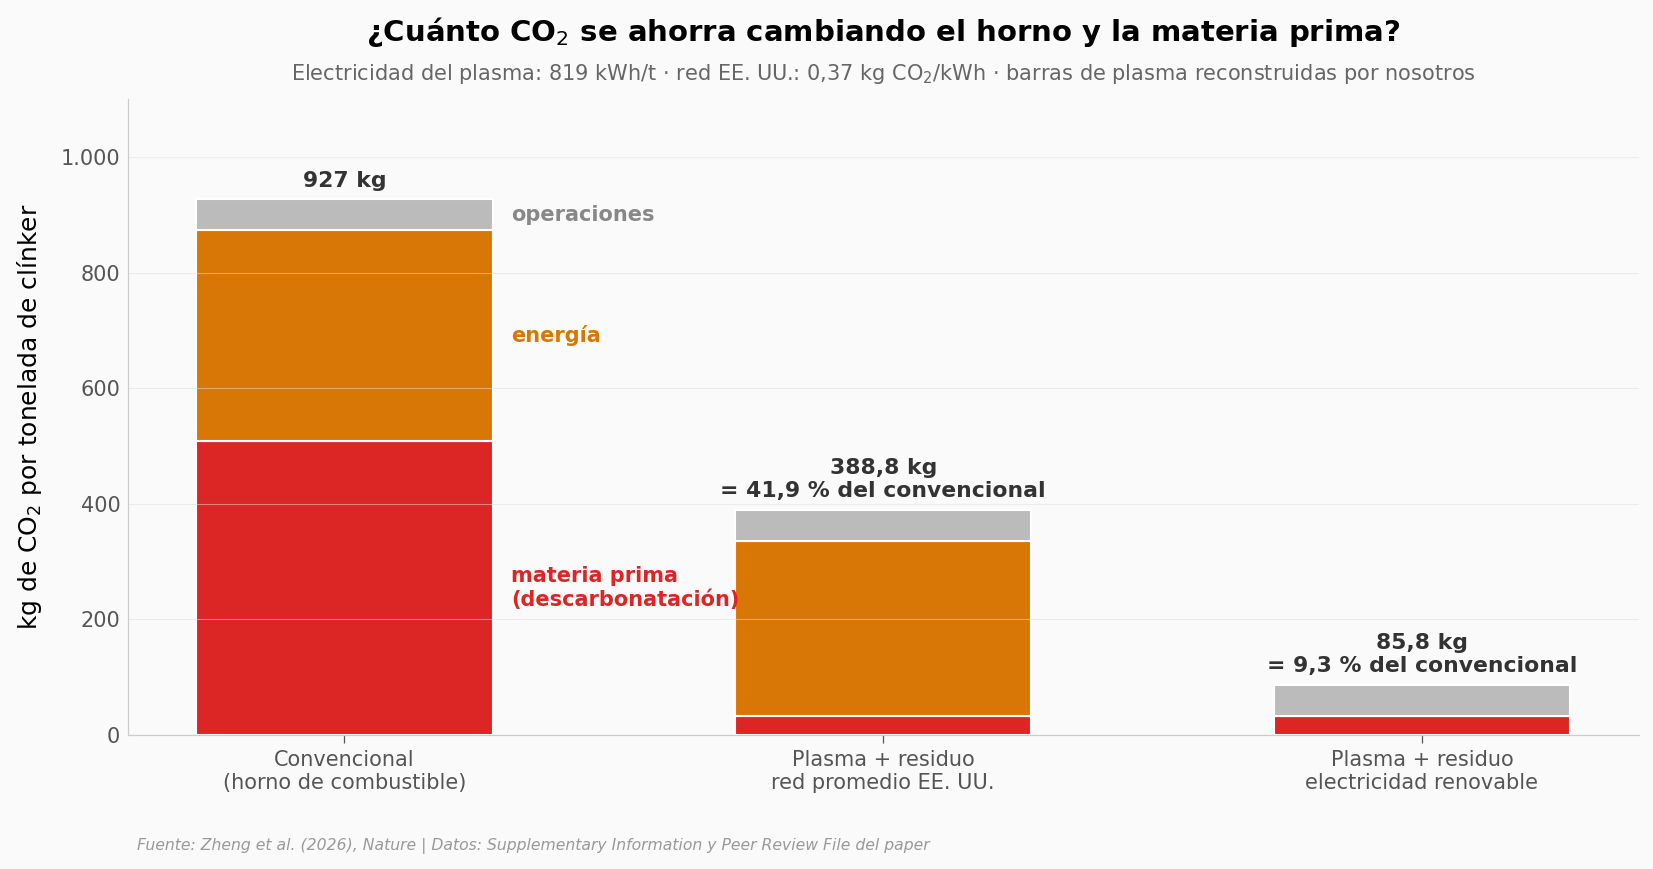

Convencional: 509 + 365 + 53 = 927 kg CO₂/t clínker (54,9 / 39,4 / 5,7 %)
Materia prima: 509 → 32,8 kg (−93,6 %)
Plasma renovable: 85,8 kg (9,3 % del convencional)
Plasma con red EE. UU. y 819 kWh/t: 388,8 kg (41,9 % del convencional)
Plasma con red EE. UU. y 710 kWh/t: 348,5 kg (37,6 % del convencional)
Tabla S3 (proyección global): 2,42 Gt CO₂/año = 0,85 (materias primas) + 1,57 (combustible, 64,9 %)


In [5]:
cv = co2[co2['proceso'] == 'convencional'].set_index('componente')['kg_co2_t']
mat_conv = cv['materias primas (descarbonatación)']
ene_conv = cv['energía']
ope = cv['operaciones']
mat_plasma = co2.loc[co2['proceso'] == 'plasma', 'kg_co2_t'].iloc[0]
kwh_sinter = tea.loc['electricidad_sinterizado_plasma', 'valor_min']
factor_red_eeuu = tea.loc['factor_emision_electricidad', 'valor_max']
total_conv = mat_conv + ene_conv + ope

# Reconstrucción nuestra: materia prima del residuo + las mismas operaciones del convencional
# + la electricidad × el factor de la red. Con renovable (factor 0) da el ≈ 86 kg del texto.
escenarios = {
    'Convencional\n(horno de combustible)': (mat_conv, ene_conv, ope),
    'Plasma + residuo\nred promedio EE. UU.': (mat_plasma, factor_red_eeuu * KWH_POR_TONELADA, ope),
    'Plasma + residuo\nelectricidad renovable': (mat_plasma, 0.0, ope),
}
partes = [('Materia prima (descarbonatación)', COLOR_ALERTA), ('Energía', COLOR_REFERENCIA), ('Operaciones', COLOR_GRIS)]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(escenarios))
abajo = np.zeros(len(escenarios))
valores = np.array(list(escenarios.values()))
for j, (nombre, color) in enumerate(partes):
    ax.bar(x, valores[:, j], bottom=abajo, color=color, width=0.55, edgecolor='white', linewidth=1)
    abajo += valores[:, j]
totales = valores.sum(axis=1)
for i, t in enumerate(totales):
    extra = '' if i == 0 else f"\n= {es(f'{t / total_conv * 100:.1f}')} % del convencional"
    ax.text(x[i], t + 15, f"{es(f'{round(t, 1):g}')} kg{extra}", ha='center', va='bottom', fontsize=10.5,
            fontweight='bold', color='#333333')
ax.text(0.31, mat_conv / 2, 'materia prima\n(descarbonatación)', color=COLOR_ALERTA, fontsize=10, fontweight='bold', ha='left', va='center')
ax.text(0.31, mat_conv + ene_conv / 2, 'energía', color=COLOR_REFERENCIA, fontsize=10, fontweight='bold', ha='left', va='center')
ax.text(0.31, total_conv - ope / 2, 'operaciones', color='#888888', fontsize=10, fontweight='bold', ha='left', va='center')
ax.set_xticks(x)
ax.set_xticklabels(list(escenarios.keys()), fontsize=10)
ax.set_ylim(0, 1100)
ax.set_ylabel('kg de CO$_2$ por tonelada de clínker')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: es(f'{v:,.0f}')))
ax.set_title('¿Cuánto CO$_2$ se ahorra cambiando el horno y la materia prima?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f"Electricidad del plasma: {KWH_POR_TONELADA} kWh/t · red EE. UU.: {es(factor_red_eeuu)} kg CO$_2$/kWh · barras de plasma reconstruidas por nosotros",
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/co2_por_tonelada.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Convencional: {mat_conv:.0f} + {ene_conv:.0f} + {ope:.0f} = {total_conv:.0f} kg CO₂/t clínker '
   f'({mat_conv/total_conv*100:.1f} / {ene_conv/total_conv*100:.1f} / {ope/total_conv*100:.1f} %)')
pr(f'Materia prima: {mat_conv:.0f} → {mat_plasma} kg ({(mat_plasma/mat_conv-1)*100:+.1f} %)')
pr(f'Plasma renovable: {mat_plasma + ope:.1f} kg ({(mat_plasma + ope)/total_conv*100:.1f} % del convencional)')
for kwh in [KWH_POR_TONELADA, kwh_sinter]:
    t = mat_plasma + ope + factor_red_eeuu * kwh
    pr(f'Plasma con red EE. UU. y {kwh:.0f} kWh/t: {t:.1f} kg ({t/total_conv*100:.1f} % del convencional)')
g = glob.set_index('componente')['gt_co2_anio']
pr(f"Tabla S3 (proyección global): {g['total']} Gt CO₂/año = {g['materias primas']} (materias primas) + "
   f"{g['combustible fósil']} (combustible, {g['combustible fósil']/g['total']*100:.1f} %)")

Aquí se ve por qué no basta con cambiar el combustible. En el horno de siempre, más de la mitad del CO₂ (509 de 927 kg por tonelada de clínker, el 54,9 %) no viene del fuego sino de la caliza al descomponerse: aunque quemaras hidrógeno, esa parte seguiría ahí. Según las cuentas de los autores, usar pasta de cemento de demolición como materia prima la baja a 32,8 kg, un 93,6 % menos (los autores dicen "más de 93 %").

Lo demás depende de dónde salga la electricidad. Con energía renovable, nuestra reconstrucción da 85,8 kg, el 9,3 % del convencional; el texto revisado que los autores proponen en el expediente dice unos 86 (y su respuesta a los revisores, 80). Con la red promedio de EE. UU. y los 819 kWh/t de la figura R6 sube a 388,8 kg, el 41,9 % del convencional; si solo contamos los 710 kWh/t del sinterizado, queda en 37,6 %. Los autores dicen "aproximadamente 40 %", y las dos cuentas caen cerca.

Dos advertencias. Las barras de plasma son una reconstrucción nuestra: suponemos las mismas operaciones que el convencional (53 kg), que es lo que hace cuadrar los 86 kg del texto. Y las unidades bailan: la revisión habla de kg por tonelada de **clínker**, pero el texto de los 86 kg y la figura R6 (de donde sale el 819) van por tonelada de **cemento**.

A escala mundial, la Tabla S3 proyecta 2,42 gigatoneladas de CO₂ menos al año, 64,9 % de ellas por dejar el combustible fósil, sin que el SI detalle con qué supuesto de adopción. Es la salida de un modelo, no una medición.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| Los tres clínkeres superan el 70 % de alita + belita que pide la norma | ✅ | COMM 79,3 %, NEW 81,4 %, RCL 78,2 % (el paper: "más de 75 %" para NEW y RCL). Una refinación Rietveld por clínker, sin barras de error |
| El clínker de plasma tiene más alita que el comercial | ⚠️ | +8,6 puntos de alita y −6,5 de belita, pero con n = 1 por clínker no hay forma de separar el efecto de la variación entre lotes. Sin prueba estadística posible |
| El clínker hecho con residuo de cemento se parece al comercial | ⚠️ | 1,2 puntos menos de alita y alita + belita de 78,2 % frente a 79,3 %, pero con n = 1 no sabemos si esa diferencia cabe en la variación entre lotes. Solo composición: la resistencia y la hidratación no las pudimos reproducir |
| A 0,07 USD/kWh la tonelada cuesta 78 USD, con la energía cerca del 72 % | ⚠️ | El expediente trae una versión revisada de la misma frase: 83,7 USD/t con 83 % de energía, que coincide con la figura R6 (83,6) y con el punto de partida de la curva S21 (500.000 t/año). Con la pendiente de R6 (819 kWh/t, R² = 0,99998) la energía sería el 68,6 % |
| Con luz a 0,04 USD/kWh el costo baja a 45,5 USD/t | ❌ | La figura R6 marca 59,1 USD/t a 0,04 USD/kWh; desde el 78 del SI saldrían 53,9. 45,5 corresponde a unos 0,0295 USD/kWh. La versión revisada del expediente dice 51,2, que tampoco cuadra con R6. No vemos la figura final 4e |
| Con luz a 0,02 USD/kWh el costo baja a 38,5 USD/t | ⚠️ | Desde el 78 de la primera versión sale 37,9 USD/t, pero la figura R6, que la propia frase cita, marca 42,8 USD/t a 0,02 USD/kWh |
| Con la red de EE. UU., el CO₂ queda en torno al 40 % del convencional | ✅ | 41,9 % con los 819 kWh/t de la figura R6 y 37,6 % con los 710 kWh/t del sinterizado. Las barras de plasma son reconstrucción nuestra |
| Con electricidad renovable quedan unos 86 kg de CO₂ por tonelada | ✅ | 32,8 + 53 = 85,8 kg, el 9,3 % del convencional; el texto revisado del expediente dice unos 86. Unidades mezcladas: clínker en las cuentas, cemento en ese texto |
| El método permitiría producir cemento barato a escala | ⚠️ | Es la salida de un modelo de costos, no de una planta. A 0,07 USD/kWh sale entre 24,3 y 30,0 USD/t más caro que el convencional (53,7), según la versión del texto; queda bajo el precio de mercado de 120–150 USD/t. El abstract dice que el método lo "permite"; el SI habla de "potencial" para competir. Lo que hay detrás es un modelo, no una planta |

> **Limitaciones:** (1) El cuerpo del paper está tras un muro de pago: trabajamos con el SI y el expediente de revisión por pares, cuyas figuras R6 y R7 son versiones previas de las figuras 4e y 4f finales, y cuyo texto trae dos versiones de las cifras de costo. (2) Las curvas de costo (R6, S21) están digitalizadas de imágenes; el residuo máximo de la calibración fue de 0,40 USD/t. (3) Todo el bloque de costos y CO₂ sale del modelo de los autores: son proyecciones, no mediciones de una planta. (4) La resistencia a la compresión, el calor de hidratación y la microscopía electrónica en tiempo real (con la que los autores reportan que el desorden en la superficie del clínker acelera su reactividad) vienen solo como imágenes o video: no los reproducimos. (5) El paper habla de una eficiencia de calentamiento de hasta 80 % con 2,5 GJ por tonelada; con el calor teórico de 1,6–1,8 GJ nos da 64–72 %, así que probablemente miden cosas distintas y no las mezclamos.

## Ahora tú

1. **¿A qué precio de la luz el cemento de plasma empataría con el convencional?** Pista: despeja el precio para el que `b + KWH_POR_TONELADA * precio` (la recta de la figura R6) iguala `costo_conv`.
2. **¿Cuánto CO₂ emitiría con la red eléctrica de tu país?** Pista: busca el factor de emisión de tu red (kg de CO₂ por kWh), ponlo en `FACTOR_RED` en la celda de configuración y vuelve a correr la celda de abajo.
3. **¿Qué pasa si la planta usa solo los 710 kWh/t del sinterizado?** Pista: cambia `KWH_POR_TONELADA` a 710 y compara costo y CO₂ con los de 819.

In [6]:
# --- EXPERIMENTA AQUÍ ---
# Costo y CO₂ de una tonelada con TU precio de electricidad, TU red y TU consumo por tonelada
costo = b + KWH_POR_TONELADA * PRECIO_KWH       # la recta de la figura R6, con tu electricidad por tonelada
co2_t = mat_plasma + ope + FACTOR_RED * KWH_POR_TONELADA
empate = (costo_conv - b) / KWH_POR_TONELADA
pr(f'Con luz a {PRECIO_KWH} USD/kWh: {costo:.1f} USD/t (convencional: {costo_conv:.1f}; mercado: {MERCADO[0]}–{MERCADO[1]})')
pr(f'Con {FACTOR_RED} kg CO₂/kWh y {KWH_POR_TONELADA} kWh/t: {co2_t:.1f} kg CO₂/t ({co2_t / total_conv * 100:.1f} % del convencional)')
pr(f'Precio de la luz al que el plasma empata con el convencional: {empate:.4f} USD/kWh')
# Factor de red al que el plasma emitiría lo mismo que el horno convencional
pr(f'Factor de red que igualaría al convencional: {(total_conv - mat_plasma - ope) / KWH_POR_TONELADA:.2f} kg CO₂/kWh')

Con luz a 0,07 USD/kWh: 83,6 USD/t (convencional: 53,7; mercado: 120–150)
Con 0,37 kg CO₂/kWh y 819 kWh/t: 388,8 kg CO₂/t (41,9 % del convencional)
Precio de la luz al que el plasma empata con el convencional: 0,0335 USD/kWh
Factor de red que igualaría al convencional: 1,03 kg CO₂/kWh


## Créditos

**Paper:** Zheng et al. (2026). *Sustainable cement production via a liquid-phase pathway*. Nature. DOI: [10.1038/s41586-026-11313-w](https://doi.org/10.1038/s41586-026-11313-w) · cuerpo del artículo con muro de pago.

**Datos:** Supplementary Information (MOESM1: Figs. S7-S9, S21 y Tablas S2-S3) y Peer Review File (MOESM2: Fig. R6 y cuentas de CO₂), ambos del mismo DOI. Transcribimos las tablas y cifras a CSV y digitalizamos las figuras R6 y S21.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [Sustainable cement production via a liquid-phase pathway](https://doi.org/10.1038/s41586-026-11313-w)  
*Nature, 2026-11-25 · paywall*

**Supplementary Material**: [Supplementary Information (MOESM1): Notes 1-11, Figs. S1-S21, Tables S1-S5 — Sustainable cement production via a liquid-phase pathway](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11313-w/MediaObjects/41586_2026_11313_MOESM1_ESM.pdf)  
*Nature, 2026-11-25*

**Supplementary Material**: [Peer Review File (MOESM2): Figs. R5-R10, análisis tecnoeconómico y de CO₂ — Sustainable cement production via a liquid-phase pathway](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11313-w/MediaObjects/41586_2026_11313_MOESM2_ESM.pdf)  
*Nature, 2026-11-25*

*23 afirmaciones del notebook verificadas contra estas fuentes*